# MLT Assignment #1: Bioresponse, decision trees and random forests

Mironov Kirill, group J4132

Data: `bioresponse.csv`. Each row is a molecule. `Activity` is the target (1 if the molecule caused a biological response, 0 if not), `D1 ... D1776` are molecular descriptors, already normalized.

What is done:
1. Four classifiers: a small decision tree, a deep decision tree, a random forest on small trees and a random forest on deep trees. Train / test split 75% / 25%.
2. Metrics: precision, recall, accuracy, F1-score, log-loss.
3. Precision-recall and ROC curves.
4. A classifier that avoids Type II errors (False Negatives) with recall above 0.95.
5. Conclusions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, accuracy_score, f1_score, log_loss,
                             precision_recall_curve, roc_curve, average_precision_score, roc_auc_score,
                             confusion_matrix)

RANDOM_STATE = 42

## 1. Data

In [2]:
df = pd.read_csv('bioresponse.csv')
print('shape:', df.shape)
print('NaN values:', df.isna().sum().sum())
print(df['Activity'].value_counts(normalize=True).rename('share').round(3))
df.iloc[:5, :8]

shape: (3751, 1777)
NaN values: 0
Activity
1    0.542
0    0.458
Name: share, dtype: float64


,Activity,D1,D2,D3,D4,D5,D6,D7
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361


3751 molecules, 1776 numeric features, no missing values. 54% of the molecules are active, so the classes are almost balanced. Trees don't need scaling, so I use the features as they are.

The split is 75 / 25, stratified by `Activity`.

In [3]:
X = df.drop(columns='Activity')
y = df['Activity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print('train:', X_train.shape, ' test:', X_test.shape)
print('share of 1 in train / test: %.3f / %.3f' % (y_train.mean(), y_test.mean()))

train: (2813, 1776)  test: (938, 1776)
share of 1 in train / test: 0.542 / 0.543


## 2. Task 1: four classifiers

- small tree: `max_depth=3` (at most 8 leaves);
- deep tree: no depth limit, grows until the leaves are pure;
- random forest on small trees: 300 trees with `max_depth=3`;
- random forest on deep trees: 300 trees without a depth limit.

In the forests every split is chosen from `max_features='sqrt'`, about 42 random features, so the trees are less correlated and averaging works better.

In [4]:
models = {
    'Small tree': DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    'Deep tree': DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE),
    'RF small trees': RandomForestClassifier(n_estimators=300, max_depth=3, n_jobs=-1, random_state=RANDOM_STATE),
    'RF deep trees': RandomForestClassifier(n_estimators=300, max_depth=None, n_jobs=-1, random_state=RANDOM_STATE),
}
for name, model in models.items():
    model.fit(X_train, y_train)

for name in ['Small tree', 'Deep tree']:
    t = models[name]
    print(f'{name}: depth {t.get_depth()}, leaves {t.get_n_leaves()}')
depths = [e.get_depth() for e in models['RF deep trees'].estimators_]
print(f'RF deep trees: depth of the trees from {min(depths)} to {max(depths)}')

Small tree: depth 3, leaves 8
Deep tree: depth 46, leaves 337
RF deep trees: depth of the trees from 19 to 45


## 3. Task 2: metrics

Precision, recall, accuracy and F1 are computed from the predicted labels, log-loss from `predict_proba`. I also print the train metrics to see overfitting.

In [5]:
def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {'precision': precision_score(y_true, pred),
            'recall': recall_score(y_true, pred),
            'accuracy': accuracy_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'log-loss': log_loss(y_true, proba)}


probas = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
test_metrics = pd.DataFrame({name: evaluate(y_test, p) for name, p in probas.items()}).T
train_metrics = pd.DataFrame({name: evaluate(y_train, m.predict_proba(X_train)[:, 1]) for name, m in models.items()}).T

print('TEST')
display(test_metrics.round(3))
print('TRAIN')
display(train_metrics.round(3))

TEST


,precision,recall,accuracy,F1,log-loss
Small tree,0.754,0.752,0.732,0.753,0.724
Deep tree,0.717,0.766,0.709,0.741,10.490
RF small trees,0.708,0.756,0.698,0.731,0.604
RF deep trees,0.783,0.817,0.778,0.800,0.473


TRAIN


,precision,recall,accuracy,F1,log-loss
Small tree,0.807,0.783,0.781,0.795,0.502
Deep tree,1.000,1.000,1.000,1.000,0.000
RF small trees,0.739,0.803,0.739,0.770,0.582
RF deep trees,1.000,1.000,1.000,1.000,0.128


- The deep tree has accuracy 1.0 on train and 0.709 on test, so it overfits. Its test log-loss is 10.5 because all its probabilities are 0 or 1: every mistake costs -log(ε) ≈ 36, and 29.1% of errors × 36 ≈ 10.49.
- The small tree almost doesn't overfit (0.781 on train, 0.732 on test), but 8 leaves are too few for 1776 features.
- The forest on deep trees is the best by every metric: accuracy 0.778, F1 0.800, log-loss 0.473. Each deep tree overfits, but they are weakly correlated, and the average of 300 of them has much less variance.
- The forest on small trees is a bit worse than one small tree by accuracy (0.698 vs 0.732), but its log-loss is better (0.604 vs 0.724). Small trees have a bias problem, and averaging doesn't fix bias. Also each tree in the forest is trained on a bootstrap sample and chooses from ~42 random features per split, so it is weaker than a single tree that chooses from all 1776. The averaged probabilities are less extreme, that's why the log-loss is better.

## 4. Task 3: precision-recall and ROC curves

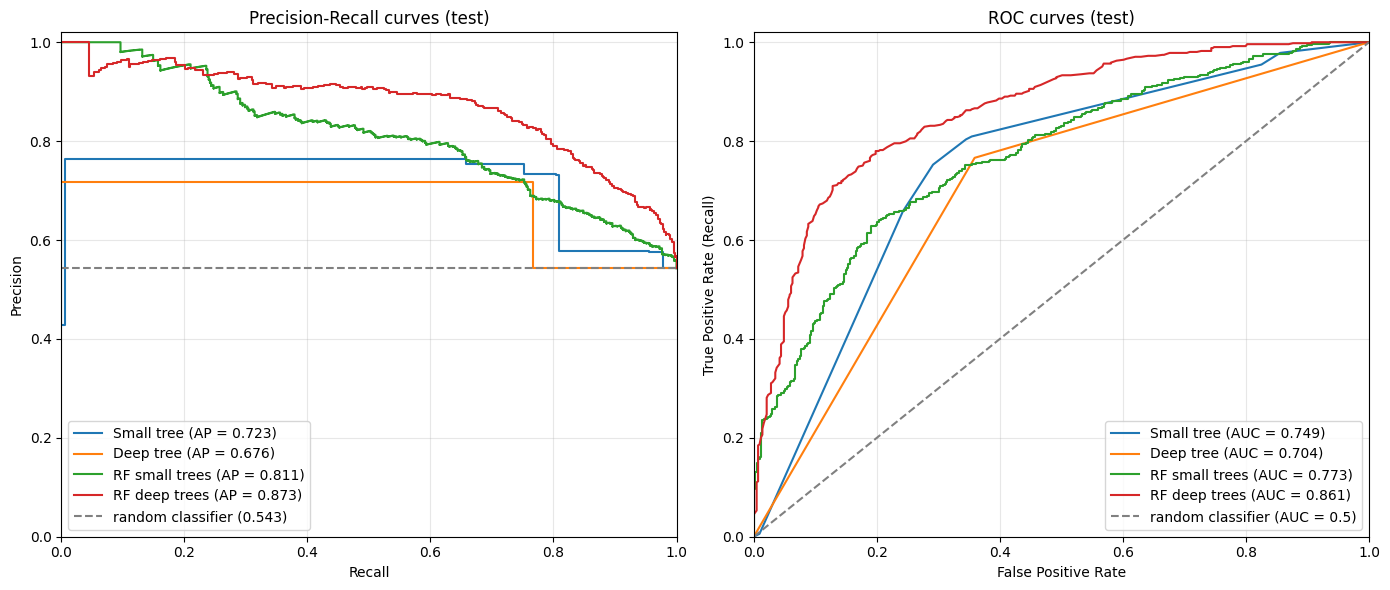

In [6]:
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(14, 6))

for name, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax_pr.plot(rec, prec, drawstyle='steps-post', label=f'{name} (AP = {average_precision_score(y_test, p):.3f})')
    fpr, tpr, _ = roc_curve(y_test, p)
    ax_roc.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')

ax_pr.axhline(y_test.mean(), color='grey', ls='--', label=f'random classifier ({y_test.mean():.3f})')
ax_pr.set(xlabel='Recall', ylabel='Precision', title='Precision-Recall curves (test)', xlim=(0, 1), ylim=(0, 1.02))
ax_pr.legend(loc='lower left')

ax_roc.plot([0, 1], [0, 1], color='grey', ls='--', label='random classifier (AUC = 0.5)')
ax_roc.set(xlabel='False Positive Rate', ylabel='True Positive Rate (Recall)', title='ROC curves (test)',
           xlim=(0, 1), ylim=(0, 1.02))
ax_roc.legend(loc='lower right')

for ax in (ax_pr, ax_roc):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PR curves are drawn as steps, because precision does not change linearly between two thresholds.

- The deep tree only has probabilities 0 and 1, so there is just one non-trivial threshold, and its ROC curve is a broken line through one point.
- The small tree has 8 leaves, so at most 8 thresholds. Its PR curve starts strangely (precision 0.43 at the strictest threshold). This is one small overfitted leaf: 18 train molecules, all active, but only 3 of its 7 test molecules are active.
- The forests give almost continuous probabilities, so their curves are smooth.
- The forest on deep trees is the highest on both plots. The forest on small trees has a better ROC-AUC than the small tree (0.773 vs 0.749) but still loses in accuracy. I checked all thresholds, and the best one gives it about 0.71, less than 0.73 for the small tree. Its ROC curve is higher only at small FPR, and near the working point of the small tree (FPR ≈ 0.3, recall ≈ 0.75) the tree is higher. AUC is averaged over all thresholds, accuracy is measured at one.

## 5. Task 4: a classifier that avoids Type II errors

A Type II error is a False Negative: an active molecule predicted as inactive.

I take the forest on deep trees (it has the best ROC curve) and lower its decision threshold below 0.5.

The threshold can't be picked on the test set, so it is chosen inside `fit`. I compute out-of-fold probabilities on train (5 folds, `cross_val_predict`) and take the largest threshold where the out-of-fold recall is at least 0.97. The largest one keeps as much precision as possible. 0.97 instead of 0.95 is a margin: there are only ~509 positives in test, and recall there can move by about 1%. After that the forest is trained again on the whole train set.

In [7]:
class LowFNClassifier(BaseEstimator, ClassifierMixin):
    """Any probabilistic classifier + a decision threshold chosen on out-of-fold train probabilities,
    so that recall is at least target_recall."""

    def __init__(self, base_estimator, target_recall=0.97, cv=5, random_state=None):
        self.base_estimator = base_estimator
        self.target_recall = target_recall
        self.cv = cv
        self.random_state = random_state

    def fit(self, X, y):
        folds = StratifiedKFold(n_splits=self.cv, shuffle=True, random_state=self.random_state)
        oof = cross_val_predict(clone(self.base_estimator), X, y, cv=folds, method='predict_proba')[:, 1]
        prec, rec, thr = precision_recall_curve(y, oof)
        ok = rec[:-1] >= self.target_recall
        best = np.flatnonzero(ok)[np.argmax(thr[ok])]
        self.threshold_ = thr[best]
        self.oof_recall_, self.oof_precision_ = rec[best], prec[best]
        self.model_ = clone(self.base_estimator).fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold_).astype(int)


low_fn = LowFNClassifier(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
                         target_recall=0.97, cv=5, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f'chosen threshold: {low_fn.threshold_:.3f}')
print(f'out-of-fold on train: recall {low_fn.oof_recall_:.3f}, precision {low_fn.oof_precision_:.3f}')

chosen threshold: 0.240
out-of-fold on train: recall 0.971, precision 0.629


,precision,recall,accuracy,F1,log-loss
"RF deep trees, threshold 0.5",0.783,0.817,0.778,0.800,0.473
"Low-FN RF, threshold 0.240",0.632,0.978,0.679,0.768,0.473


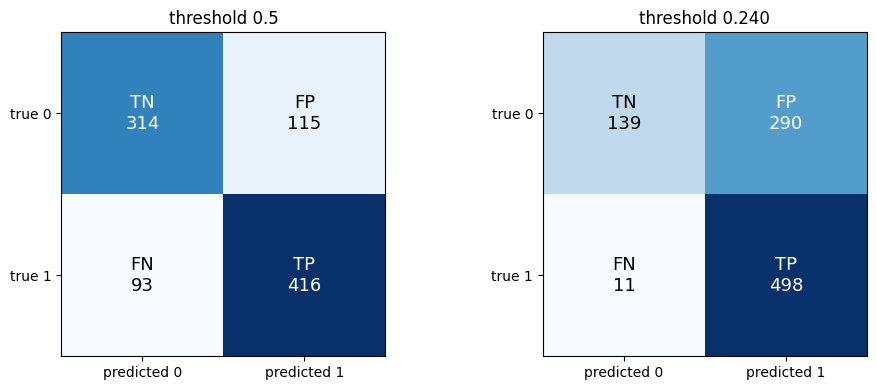

In [8]:
fn_proba = low_fn.predict_proba(X_test)[:, 1]
comparison = pd.DataFrame({'RF deep trees, threshold 0.5': evaluate(y_test, fn_proba, 0.5),
                           f'Low-FN RF, threshold {low_fn.threshold_:.3f}': evaluate(y_test, fn_proba, low_fn.threshold_)}).T
display(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, thr) in zip(axes, [('threshold 0.5', 0.5), (f'threshold {low_fn.threshold_:.3f}', low_fn.threshold_)]):
    cm = confusion_matrix(y_test, (fn_proba >= thr).astype(int))
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f'{["TN", "FP", "FN", "TP"][2 * i + j]}\n{v}', ha='center', va='center', fontsize=13,
                color='white' if v > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['predicted 0', 'predicted 1']); ax.set_yticks([0, 1], ['true 0', 'true 1'])
    ax.set_title(title)
plt.tight_layout(); plt.show()

assert comparison.iloc[1]['recall'] > 0.95

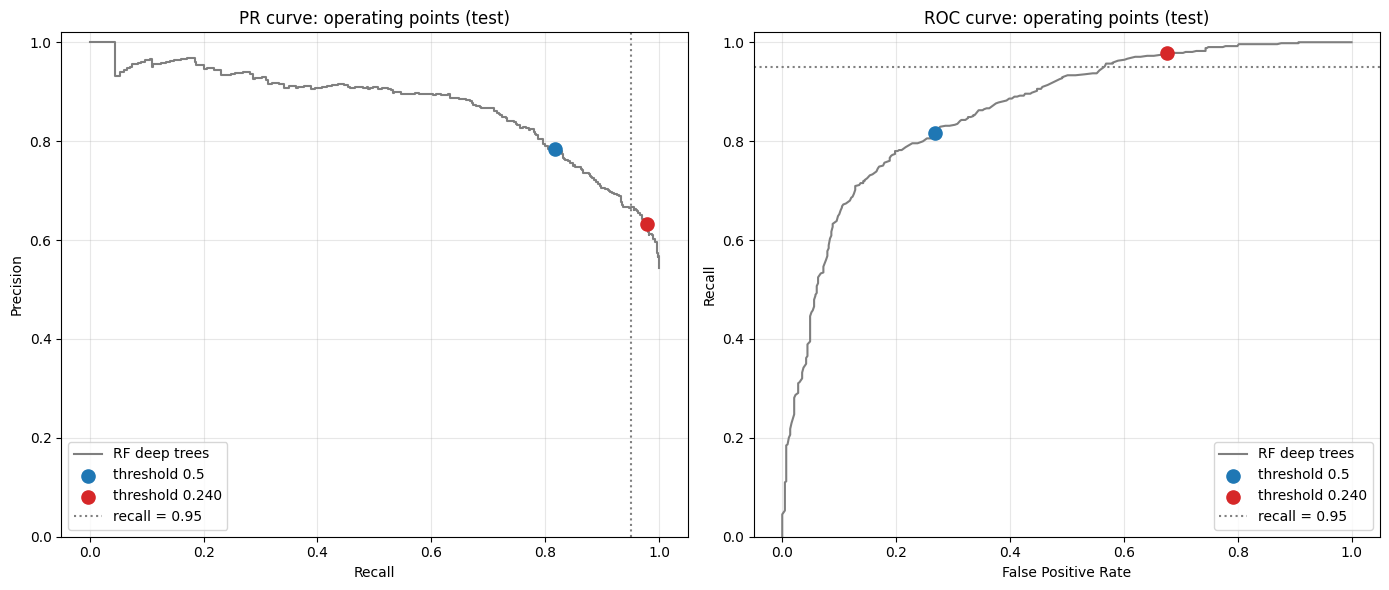

In [9]:
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(14, 6))

prec, rec, _ = precision_recall_curve(y_test, fn_proba)
ax_pr.plot(rec, prec, drawstyle='steps-post', color='tab:gray', label='RF deep trees')
fpr, tpr, _ = roc_curve(y_test, fn_proba)
ax_roc.plot(fpr, tpr, color='tab:gray', label='RF deep trees')

for thr, color, label in [(0.5, 'tab:blue', 'threshold 0.5'),
                          (low_fn.threshold_, 'tab:red', f'threshold {low_fn.threshold_:.3f}')]:
    tn, fp, fn, tp = confusion_matrix(y_test, (fn_proba >= thr).astype(int)).ravel()
    ax_pr.scatter(tp / (tp + fn), tp / (tp + fp), color=color, s=90, zorder=3, label=label)
    ax_roc.scatter(fp / (fp + tn), tp / (tp + fn), color=color, s=90, zorder=3, label=label)

ax_pr.axvline(0.95, color='grey', ls=':', label='recall = 0.95')
ax_roc.axhline(0.95, color='grey', ls=':', label='recall = 0.95')
ax_pr.set(xlabel='Recall', ylabel='Precision', title='PR curve: operating points (test)', ylim=(0, 1.02))
ax_roc.set(xlabel='False Positive Rate', ylabel='Recall', title='ROC curve: operating points (test)', ylim=(0, 1.02))
ax_pr.legend(loc='lower left'); ax_roc.legend(loc='lower right')
for ax in (ax_pr, ax_roc):
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

With the threshold 0.240 the test recall is **0.978**: 11 of 509 active molecules are missed, compared to 93 at 0.5. The cost is more false positives (290 instead of 115), precision drops from 0.783 to 0.632 and accuracy from 0.778 to 0.679. The model is the same, only the point on its PR / ROC curve moves (the red point is to the right of recall = 0.95).

Log-loss stays the same, since it doesn't depend on the threshold.

This makes sense when missing an active molecule is worse than an extra lab test, for example if the model is used as a first filter.

## 6. Conclusions

1. A single deep tree overfits: 1.0 on train, 0.709 on test, and a huge log-loss because its probabilities are only 0 and 1. A small tree doesn't overfit but is too simple (0.732).
2. The random forest on deep trees is the best model by all five metrics (accuracy 0.778, F1 0.800, log-loss 0.473) and by the PR and ROC curves.
3. A forest of small trees doesn't improve accuracy at 0.5, because the problem of small trees is bias. Its probabilities are better (lower log-loss, higher ROC-AUC), but even at its best threshold the accuracy is below the single small tree.
4. Precision, recall, accuracy and F1 depend on the threshold, log-loss measures the probabilities, and the PR and ROC curves show all thresholds at once.
5. To avoid False Negatives I lowered the threshold of the best model. The threshold was chosen on out-of-fold probabilities from train, and on test it gives recall 0.978 > 0.95 with precision 0.632.